# Airfoil optimisation 

This jupyter notebook analyses some optimisation formlations implemented in `../modules/profile_optimisation.py`. 

The general optimisation problem is formualted as follows:

- State variables: a set of Reynolds number $(Re_i)_{1 \leq i \leq M}$ at which optimise the airfoil

- Design variables: $16$ Class-Shape-Transform (CST) parameters to describe the airfoil, $\alpha$ (more generally referred to as trim variable: allowing the optimiser to optimise alpha sweeps for each airfoil and Re combination) 

The solver is the "internal" solver used in Aerosandbox (implementing IPOPT in CASaDi). 

In [37]:
## this loads the symbols that are defined in the modules 

%run ../modules/profile_optimisation.py

In [40]:
from aerosandbox.geometry import Airfoil 

airfoil = Airfoil("NACA0006")

# reynolds = np.linspace(1e5, 1e7, 10)
reynolds = np.array([0.5 * 1e6, 1e6, 1.5 * 1e6])

optimised_airfoil = optimise_airfoil(airfoil, reynolds)

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:        0
Number of nonzeros in inequality constraint Jacobian.:     1758
Number of nonzeros in Lagrangian Hessian.............:      187

Total number of variables............................:       19
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:        0
Total number of inequality constraints...............:      146
        inequality constraints with only lower bounds:      127
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:       19

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  4.1622077e-03 5.00e-01 1.35e-01   0.0 0.00e+00    -  0.00e+00 0.00e+00 

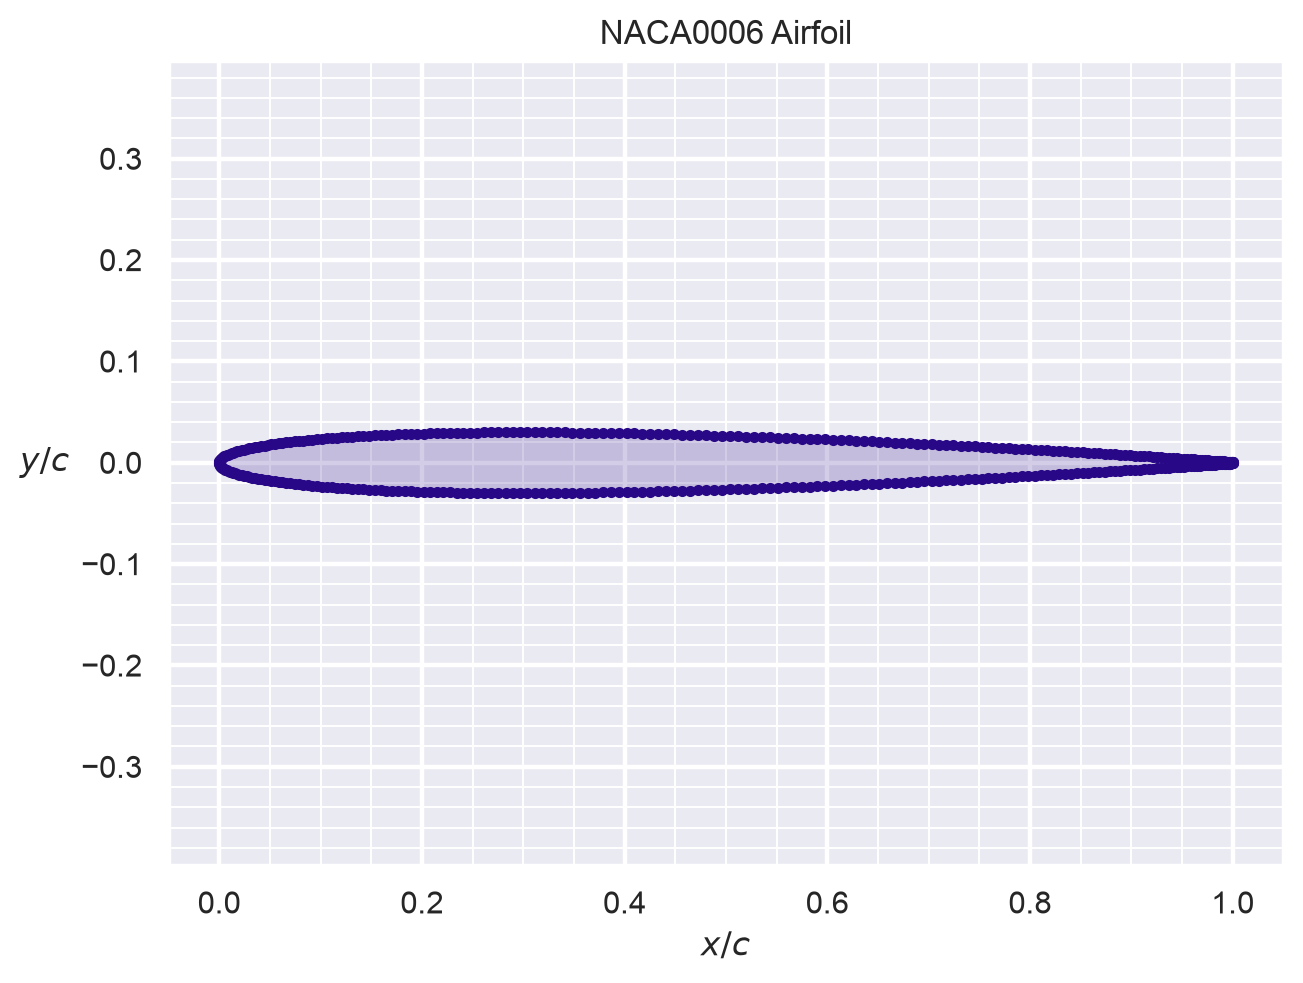

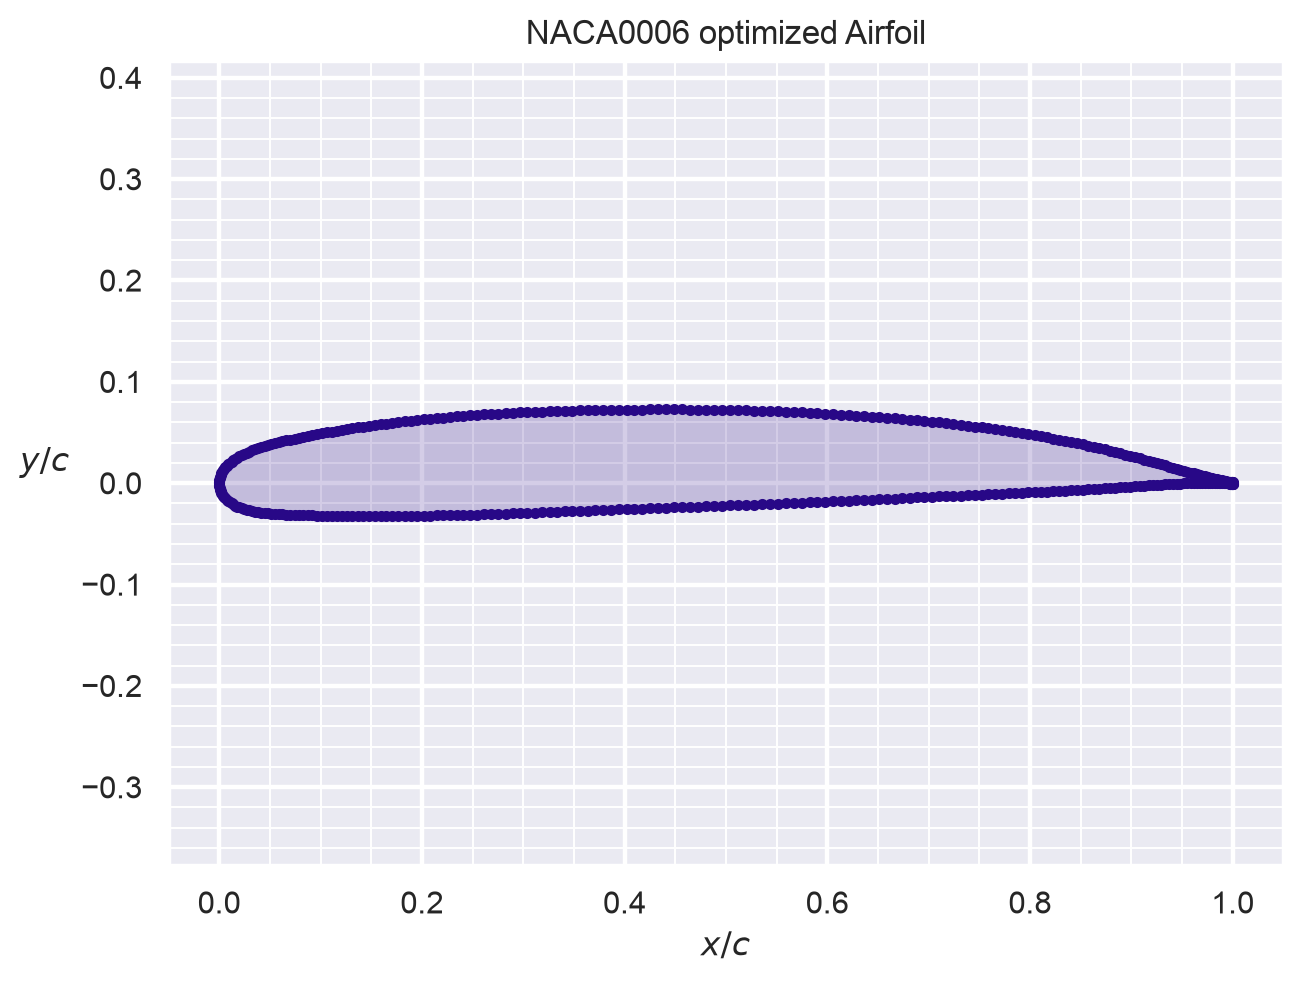

In [41]:
## Display the optimised airfoils  
from matplotlib import pyplot as plt

airfoil.draw(backend="matplotlib")
optimised_airfoil.draw(backend="matplotlib")

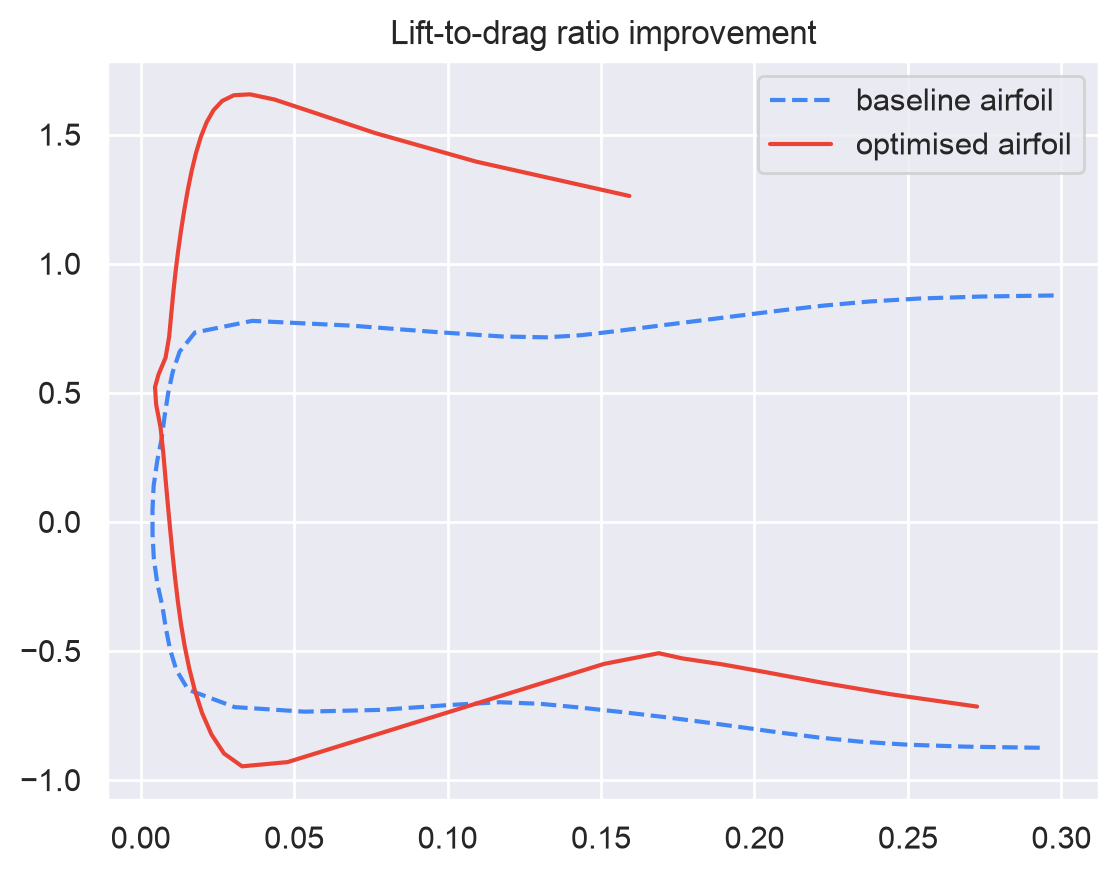

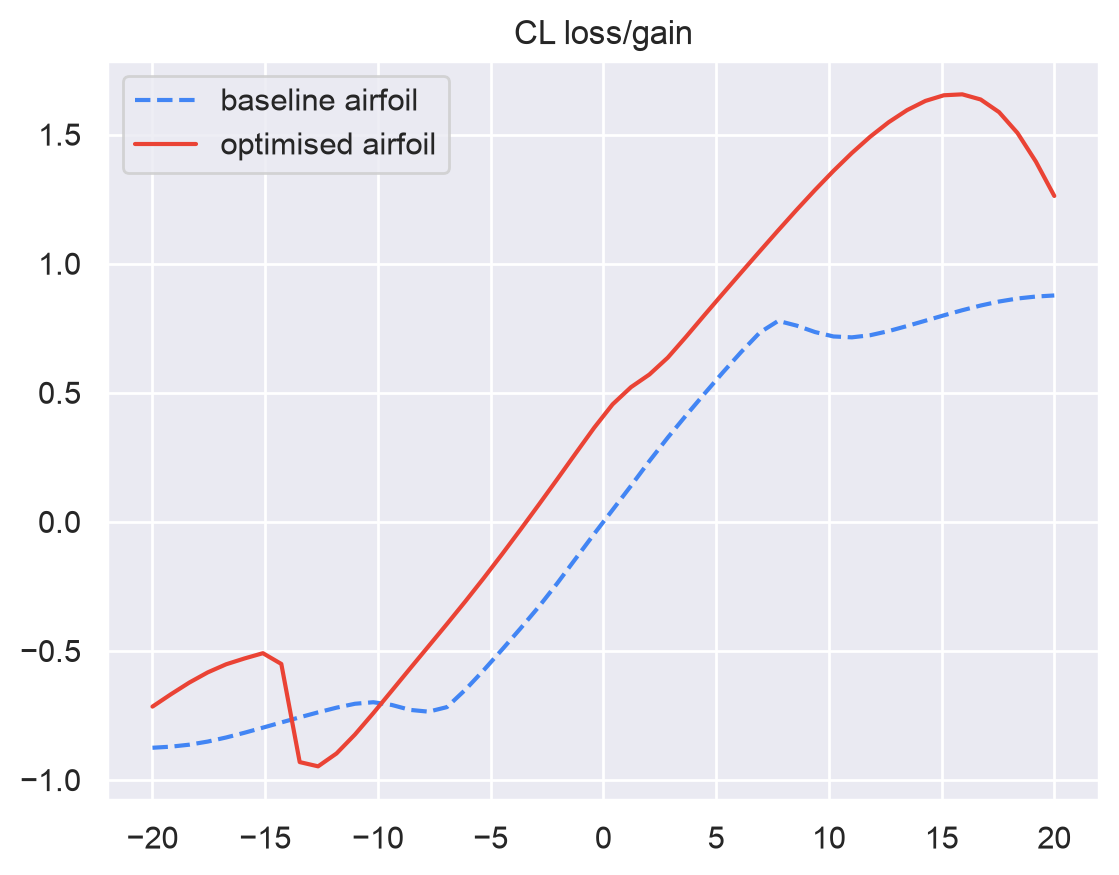

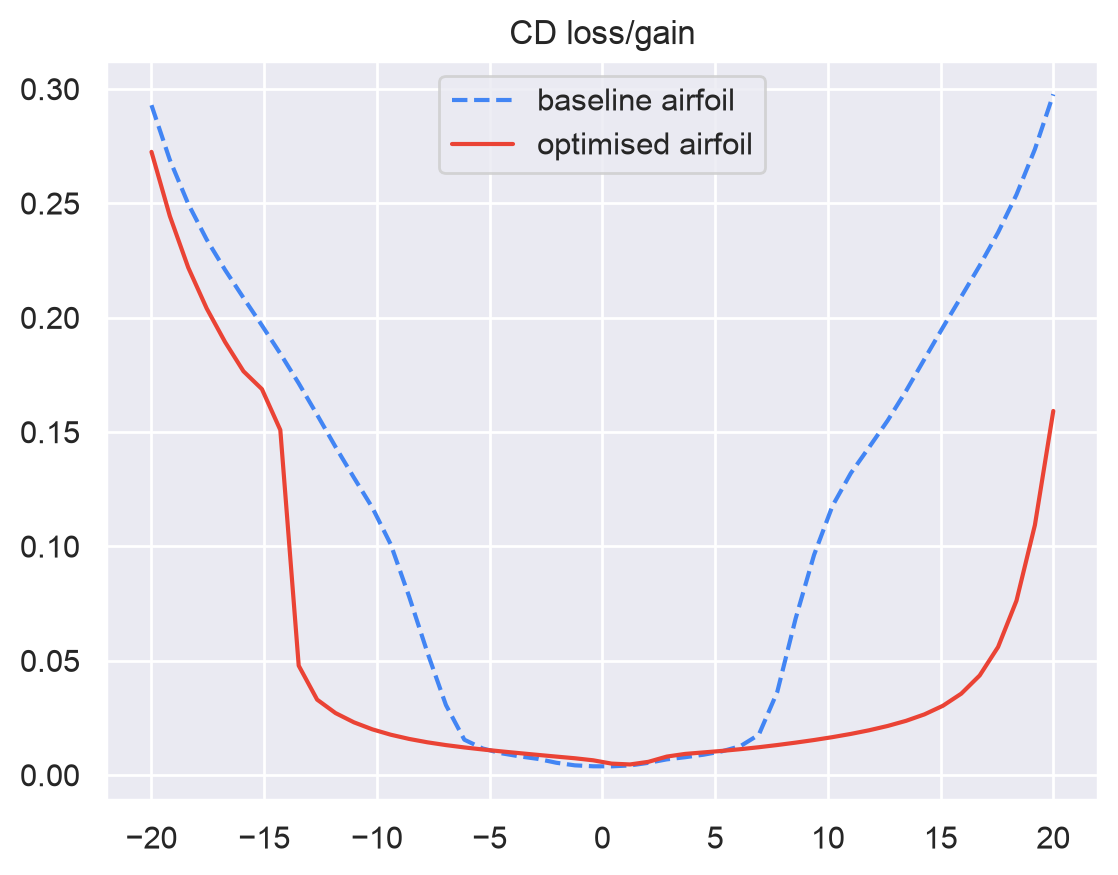

In [75]:
## aerodynamic analysis comparison 

from aerosandbox import numpy as np 
from matplotlib import pyplot as plt 

grid_res = 50 
alphas = np.linspace(-20, 20, grid_res) 
reynolds = np.linspace(0.5 * 1e6, 1.5 * 1e6, grid_res)

old_aero = airfoil.get_aero_from_neuralfoil(alpha=alphas, Re=reynolds)
new_aero = optimised_airfoil.get_aero_from_neuralfoil(alpha=alphas, Re=reynolds)

## aerodynamic polars 
plt.plot(old_aero["CD"], old_aero["CL"], label="baseline airfoil", linestyle="--")
plt.plot(new_aero["CD"], new_aero["CL"], label="optimised airfoil", linestyle="-")
plt.legend()
plt.title("Lift-to-drag ratio improvement")
plt.show()

## aerodynamic sweeps 
plt.plot(alphas, old_aero["CL"], label="baseline airfoil", linestyle="--")
plt.plot(alphas, new_aero["CL"], label="optimised airfoil", linestyle="-")
plt.legend()
plt.title("CL loss/gain")
plt.show()

plt.plot(alphas, old_aero["CD"], label="baseline airfoil", linestyle="--")
plt.plot(alphas, new_aero["CD"], label="optimised airfoil", linestyle="-")
plt.legend()
plt.title("CD loss/gain")
plt.show()

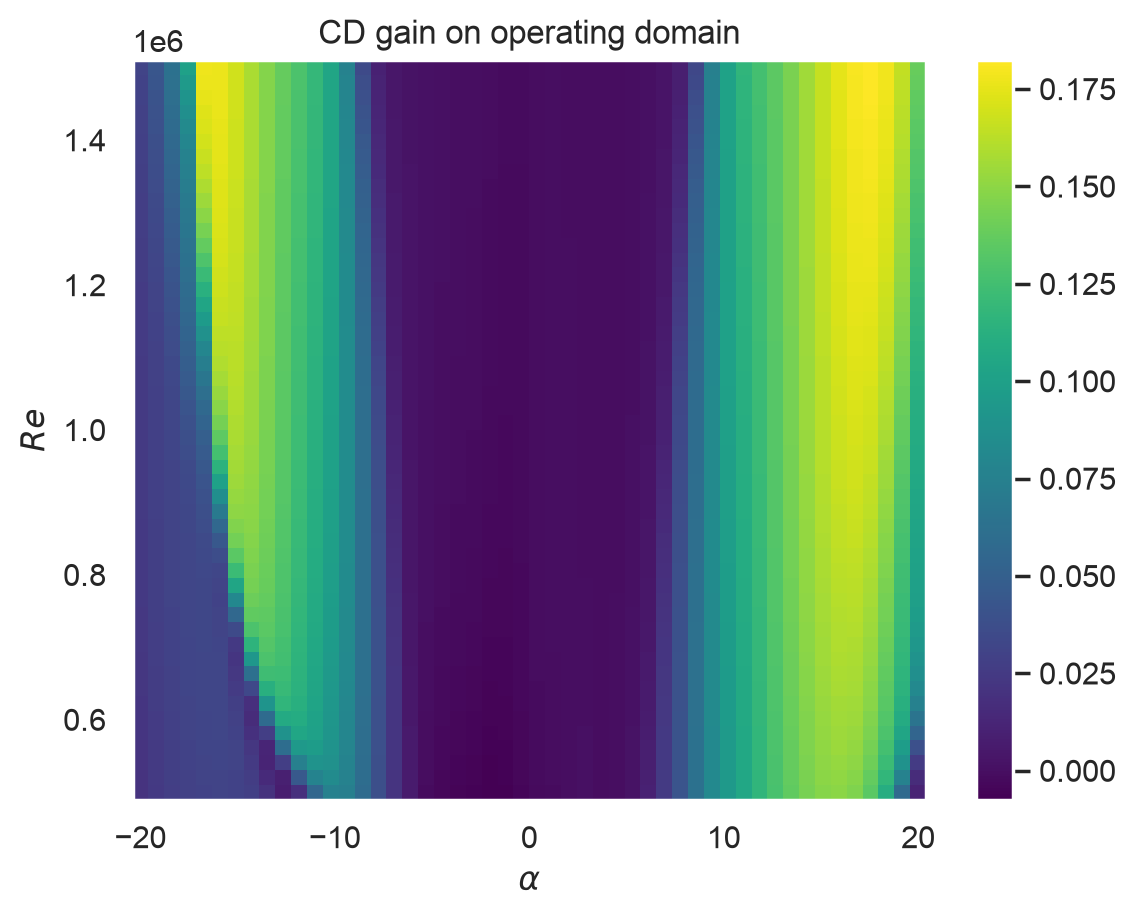

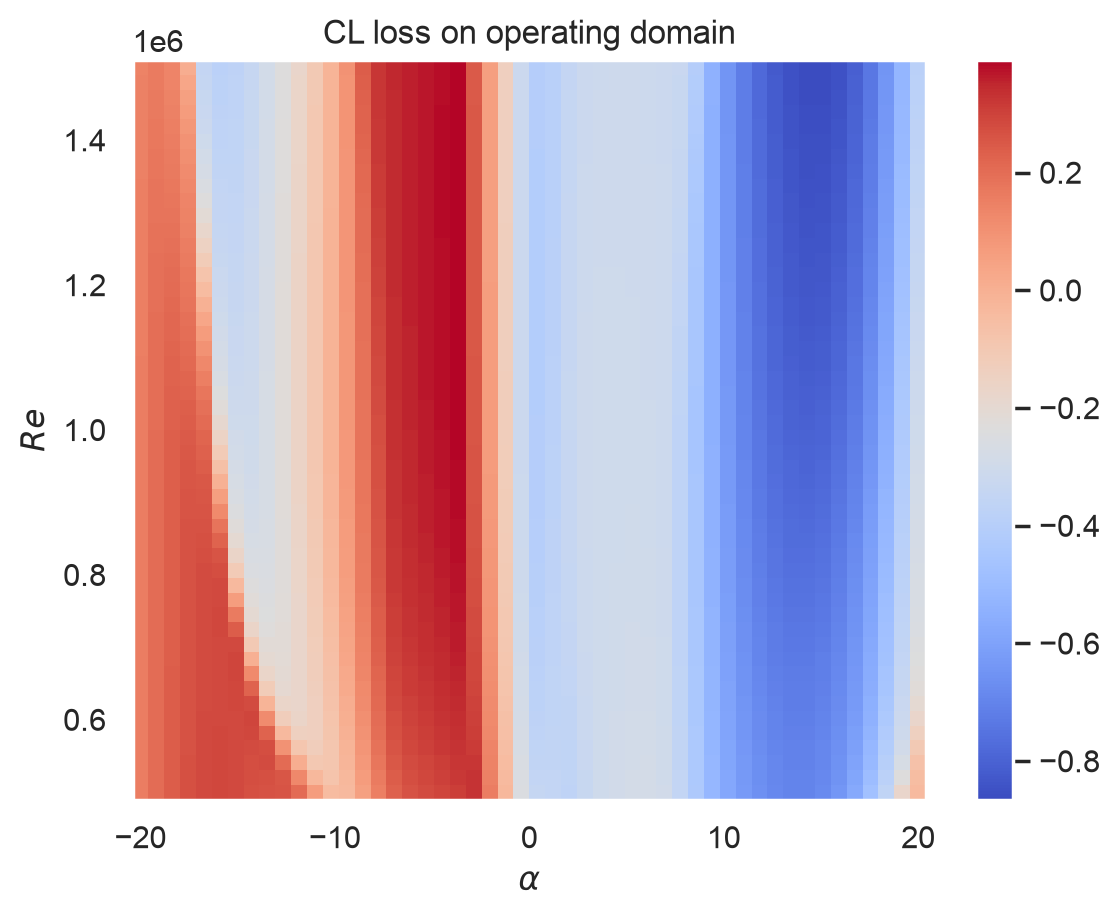

In [76]:
## aerodynamic fields analysis 
a, r = np.meshgrid(alphas, reynolds)

## compute the aerodynamic fields 
old_aero_field = airfoil.get_aero_from_neuralfoil(alpha=a.flatten(), Re=r.flatten())
new_aero_field = optimised_airfoil.get_aero_from_neuralfoil(alpha=a.flatten(), Re=r.flatten())

## compare fields 
old_cd = old_aero_field["CD"].reshape(a.shape)  
new_cd = new_aero_field["CD"].reshape(a.shape)

old_cl = old_aero_field["CL"].reshape(a.shape)
new_cl = new_aero_field["CL"].reshape(a.shape)

## plot CD gain 
pcolor = plt.pcolormesh(a, r, old_cd - new_cd, cmap="viridis")
plt.xlabel("$\\alpha$")
plt.ylabel("$Re$")
plt.title("CD gain on operating domain")

fig = plt.gcf() ## colorbar 
fig.colorbar(pcolor, ax=plt.gca())
plt.show()

## plot CL evolution 
pcolor = plt.pcolormesh(a, r, np.abs(old_cl) - np.abs(new_cl), cmap="coolwarm")
plt.xlabel("$\\alpha$")
plt.ylabel("$Re$")
plt.title("CL loss on operating domain")

fig = plt.gcf() ## colorbar 
fig.colorbar(pcolor, ax=plt.gca())
plt.show()

# Loss fields 

The $C_D$ field gain plot shows that the most gains occur on extremal $\alpha$ values, this behavior has been seen in the angle sweep. The loss in (absolute) lift coefficient is mostly seen on negative angles (Note that the resulting optimised airfoil is not symmetric). 